In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple


In [2]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [3]:
def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [4]:
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

m = 2
x = jnp.ones(m)  # input odour signal

## 9. Stepping along sparse directions in parameter space



In [5]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_570_final.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (570, 12)
Number of samples: 570
Number of parameters per sample: 12


In [6]:
U_A_sorted = np.load('reps_aligned_A.npz')['rep_A_sorted']
U_B_aligned = np.load('reps_aligned_B.npz')['rep_B_aligned']
U_C_aligned = np.load('reps_aligned_C.npz')['rep_C_aligned']
U_D_aligned = np.load('reps_aligned_D.npz')['rep_D_aligned']
# Aligned reps may be (13, k) while mitral theta has 12 weights — slice rows to match theta_opt
n_theta = int(theta_opt.shape[1])
U_A = np.asarray(U_A_sorted, dtype=float)[:n_theta, :]
U_B = np.asarray(U_B_aligned, dtype=float)[:n_theta, :]
U_C = np.asarray(U_C_aligned, dtype=float)[:n_theta, :]
U_D = np.asarray(U_D_aligned, dtype=float)[:n_theta, :]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


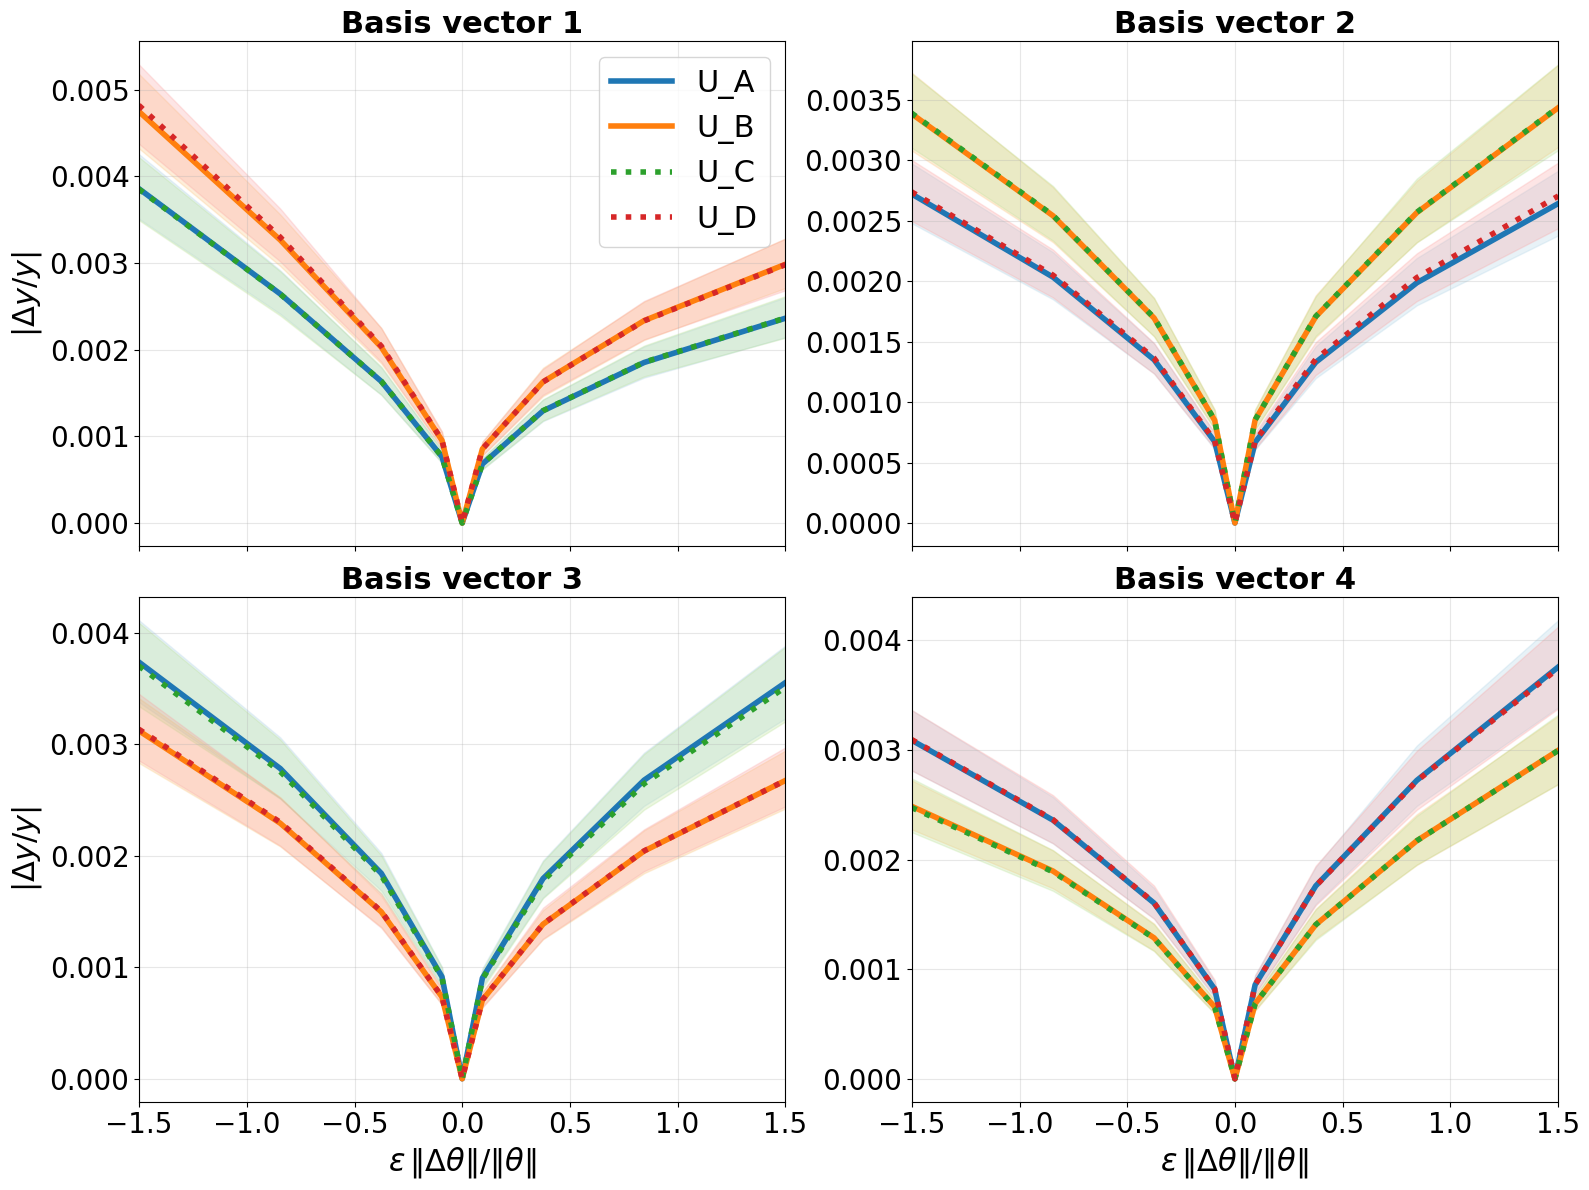

In [7]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 570

theta_opt_subset = jnp.array(theta_opt[:n_samples])

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

Us = [U_A, U_B, U_C, U_D]
u_labels = ['U_A', 'U_B', 'U_C', 'U_D']
u_shade_colors = ['#A6CEE3', '#FDBF6F', '#B2DF8A', '#FB9A99']
n_components = Us[0].shape[1]

n_rows = int(np.ceil(n_components / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(16, 12))
axes = np.atleast_1d(axes).flatten()
for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for idx, (M, u_label, shade_color) in enumerate(zip(Us, u_labels, u_shade_colors)):
    linestyle = '-' if idx < 2 else ':'
    for k in range(n_components):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)

        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * true_dir
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * true_dir) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(
            np.abs(y0_baseline) > 1e-12,
            (y_array[:, :, 0] - y0_baseline) / y0_baseline,
            y_array[:, :, 0] - y0_baseline,
        )
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        a = axes[k]
        sns.lineplot(
            x=theta_ratio_expanded,
            y=abs_rel0.ravel(),
            ax=a,
            color=shade_color,
            errorbar=('ci', 95),
            legend=False,
            linewidth=0,
            err_kws={'alpha': 0.25},
        )
        sns.lineplot(
            x=theta_ratio_expanded,
            y=abs_rel0.ravel(),
            ax=a,
            label=u_label,
            linestyle=linestyle,
            errorbar=None,
            legend=False,
            linewidth=4,
        )

n_cols = 2
for k in range(n_components):
    row, col = divmod(k, n_cols)
    axes[k].set_title(f'Basis vector {k + 1}', fontsize=22, fontweight='bold')
    axes[k].grid(True, alpha=0.3)
    axes[k].set_xlim(-1.5, 1.5)
    axes[k].tick_params(axis='both', labelsize=20)
    if row == n_rows - 1:
        axes[k].set_xlabel(r'$\epsilon \, \|\Delta \theta\| / \|\theta\|$', fontsize=22)
    else:
        axes[k].set_xlabel('')
        axes[k].tick_params(labelbottom=False)
    if col == 0:
        axes[k].set_ylabel(r'$|\Delta y / y|$', fontsize=22)
    else:
        axes[k].set_ylabel('')
axes[0].legend(fontsize=22, loc='upper right')

plt.tight_layout()
plt.savefig('Figures_final/e_stepping_along_directions_A_B_C_D.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


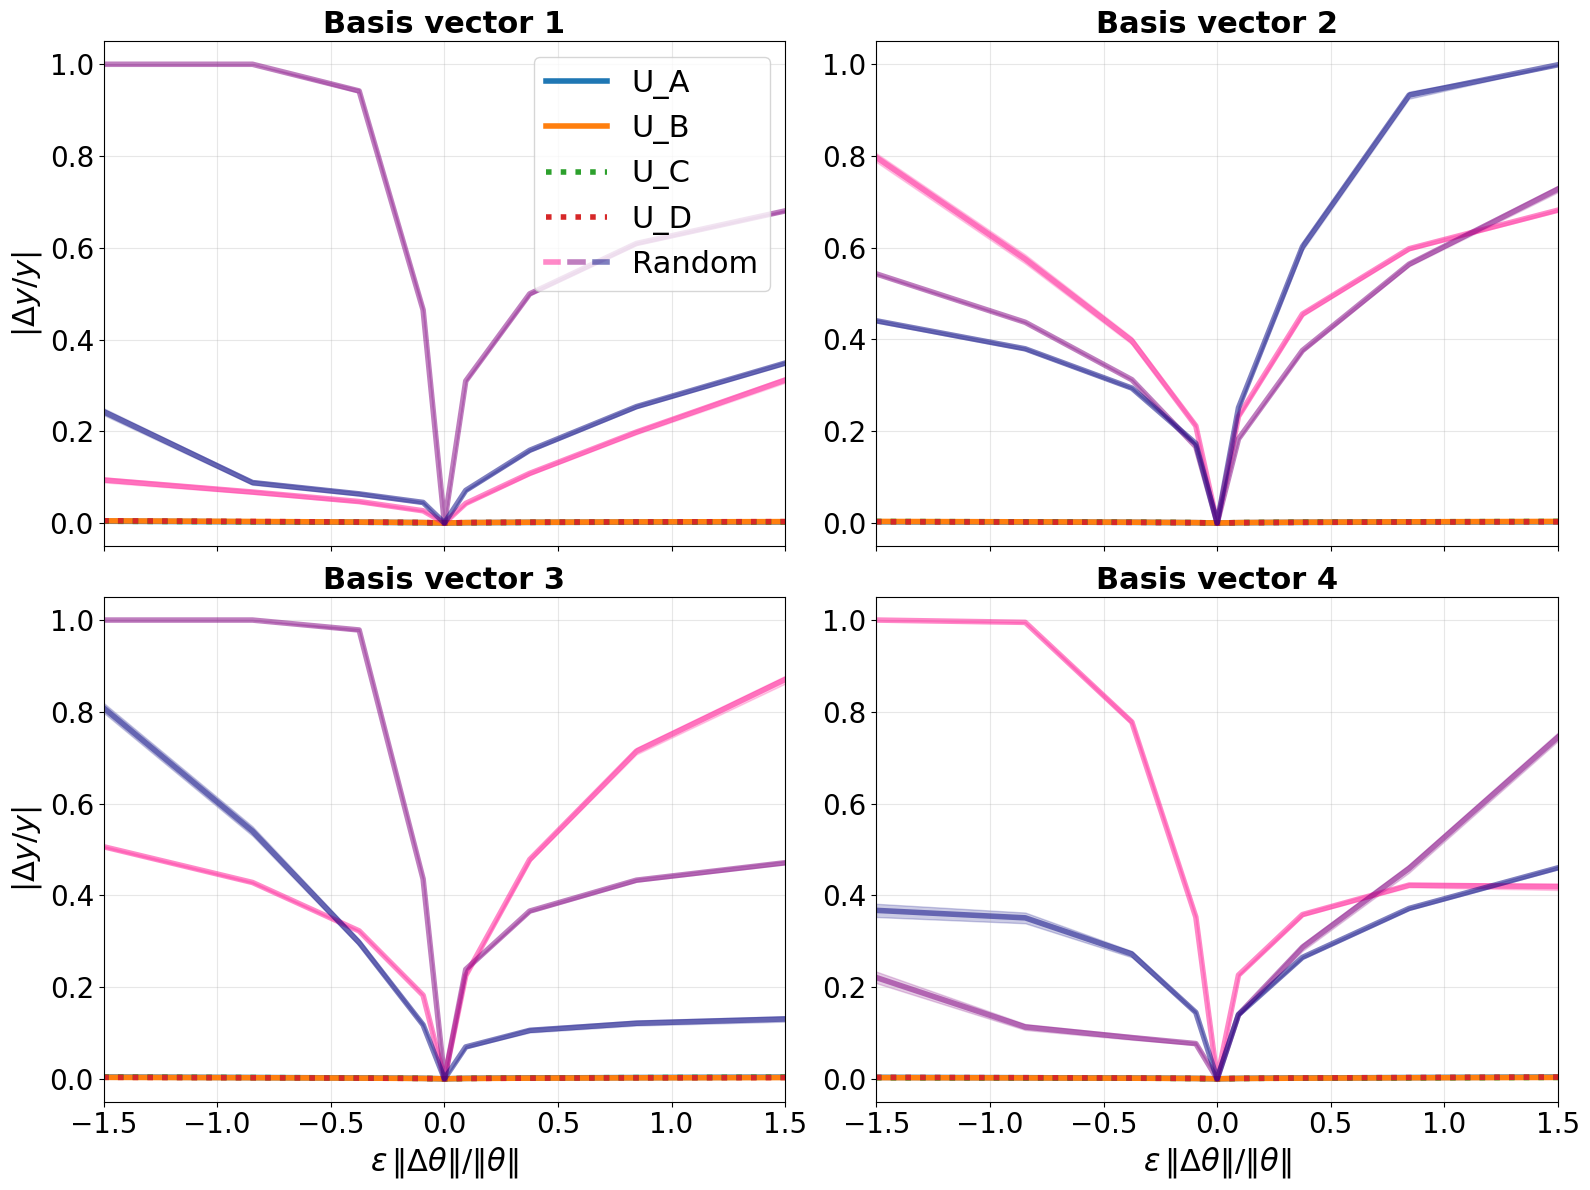

In [8]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 570
n_random = 3  # number of random directions to plot per component

theta_opt_subset = jnp.array(theta_opt[:n_samples])
key = jax.random.PRNGKey(0)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

Us = [U_A, U_B, U_C, U_D]
u_labels = ['U_A', 'U_B', 'U_C', 'U_D']
n_components = Us[0].shape[1]

random_colors = ['deeppink', 'purple', 'navy']

n_rows = int(np.ceil(n_components / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(16, 12))
axes = np.atleast_1d(axes).flatten()
for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for k in range(n_components):
    # Build named directions: U_A, U_B, U_C, U_D columns
    directions = []
    for idx, (M, u_label) in enumerate(zip(Us, u_labels)):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)
        directions.append((u_label, true_dir, f'C{idx}'))

    # Random directions: hot pink, purple, black (single combined legend entry below)
    for r in range(n_random):
        key, subkey = jax.random.split(key)
        random_dir = jax.random.normal(subkey, (Us[0].shape[0],))
        random_dir = random_dir / jnp.linalg.norm(random_dir)
        directions.append(('_nolegend_', random_dir, random_colors[r]))

    for label, direction, color in directions:
        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * direction
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * direction) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(np.abs(y0_baseline) > 1e-12,
                        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
                        y_array[:, :, 0] - y0_baseline)
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        linestyle = ':' if label in ('U_C', 'U_D') else '-'
        sns.lineplot(x=theta_ratio_expanded, y=abs_rel0.ravel(), ax=axes[k],
                     color=color, label=label, errorbar=('ci', 95), legend=False,
                     linewidth=4, alpha=0.5 if label == '_nolegend_' else 1.0,
                     linestyle=linestyle)



u_handles = [
    Line2D([0], [0], color=f'C{i}', lw=4, linestyle=':' if u_labels[i] in ('U_C', 'U_D') else '-')
    for i in range(len(u_labels))
]
random_handles = tuple(Line2D([0], [0], color=c, lw=4, alpha=0.5) for c in random_colors)

n_cols = 2
for k in range(n_components):
    row, col = divmod(k, n_cols)
    if row == n_rows - 1:
        axes[k].set_xlabel(r'$\epsilon \, \|\Delta \theta\| / \|\theta\|$', fontsize=22)
    else:
        axes[k].set_xlabel('')
        axes[k].tick_params(labelbottom=False)
    if col == 0:
        axes[k].set_ylabel(r'$|\Delta y / y|$', fontsize=22)
    else:
        axes[k].set_ylabel('')
    axes[k].set_title(f'Basis vector {k + 1}', fontsize=22, fontweight='bold')
    axes[k].grid(True, alpha=0.3)
    axes[k].set_xlim(-1.5, 1.5)
    axes[k].tick_params(axis='both', labelsize=20)
axes[0].legend(
    handles=u_handles + [random_handles],
    labels=u_labels + ['Random'],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=22,
    loc='upper right',
)

plt.tight_layout()
plt.savefig('Figures_final/e_stepping_along_directions_A_B_C_D_random.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


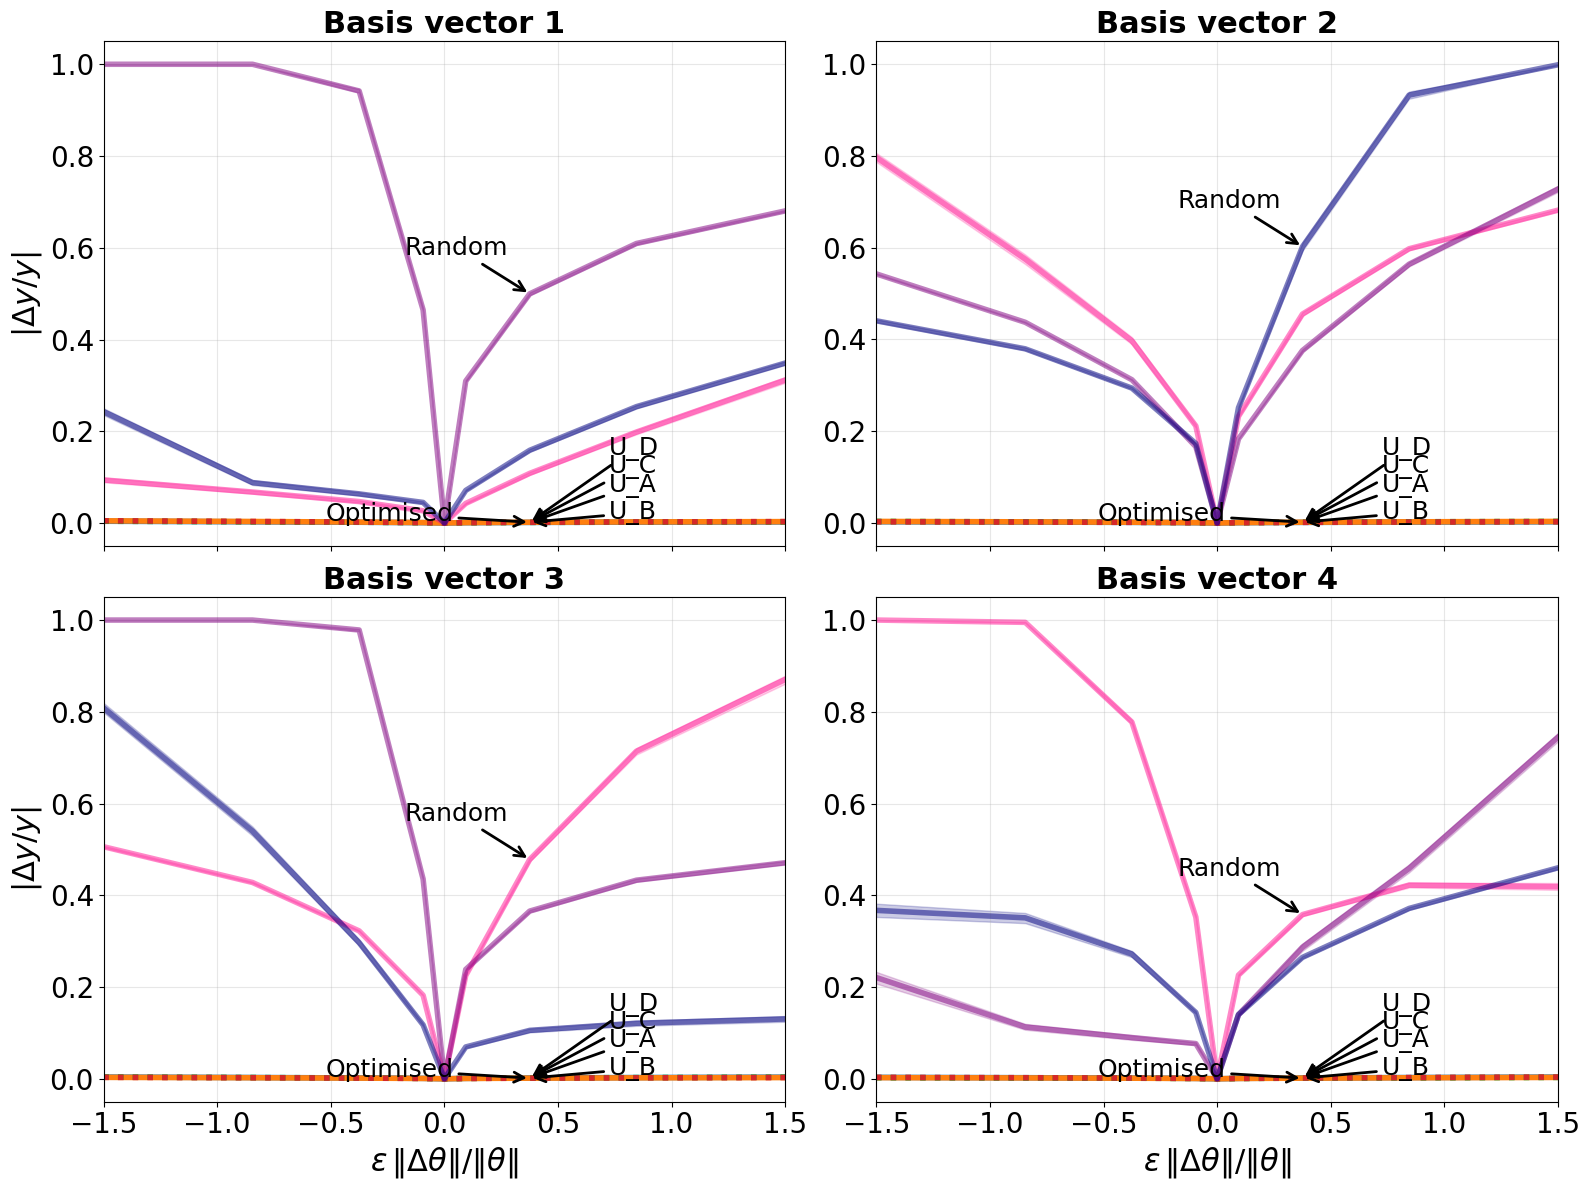

In [10]:
# Replot with arrow annotations (no legend)

e = np.arange(-2, 2 + 0.2, 0.5)
n_samples = 570
n_random = 3  # number of random directions to plot per component

theta_opt_subset = jnp.array(theta_opt[:n_samples])
key = jax.random.PRNGKey(0)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

Us = [U_A, U_B, U_C, U_D]
u_labels = ['U_A', 'U_B', 'U_C', 'U_D']
n_components = Us[0].shape[1]

random_colors = ['deeppink', 'purple', 'navy']

n_rows = int(np.ceil(n_components / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(16, 12))
axes = np.atleast_1d(axes).flatten()
for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for k in range(n_components):
    # Collect per-label mean curves for annotation
    label_to_curve = {}
    random_curves = []

    # Build named directions: U_A, U_B, U_C, U_D columns
    directions = []
    for idx, (M, u_label) in enumerate(zip(Us, u_labels)):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)
        directions.append((u_label, true_dir, f'C{idx}'))

    # Random directions
    for r in range(n_random):
        key, subkey = jax.random.split(key)
        random_dir = jax.random.normal(subkey, (Us[0].shape[0],))
        random_dir = random_dir / jnp.linalg.norm(random_dir)
        directions.append(('_random_', random_dir, random_colors[r]))

    for label, direction, color in directions:
        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * direction
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)

        theta_ratio = np.array(
            [e[i] * (np.linalg.norm(e[i] * direction) / mean_norm_theta) for i in range(len(e))]
        )
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(
            np.abs(y0_baseline) > 1e-12,
            (y_array[:, :, 0] - y0_baseline) / y0_baseline,
            y_array[:, :, 0] - y0_baseline,
        )
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        linestyle = ':' if label in ('U_C', 'U_D') else '-'
        sns.lineplot(
            x=theta_ratio_expanded,
            y=abs_rel0.ravel(),
            ax=axes[k],
            color=color,
            label=None,
            errorbar=('ci', 95),
            legend=False,
            linewidth=4,
            alpha=0.5 if label == '_random_' else 1.0,
            linestyle=linestyle,
        )

        if label in u_labels:
            label_to_curve[label] = {
                'x': theta_ratio,
                'y': abs_rel0.mean(axis=1),
            }
        elif label == '_random_':
            random_curves.append({'x': theta_ratio, 'y': abs_rel0.mean(axis=1)})

    # Arrow annotations like your example (black text + arrows)
    x_anchor = 0.5
    x_anchor_idx = int(np.argmin(np.abs(label_to_curve[u_labels[0]]['x'] - x_anchor)))

    # Offsets to keep labels separated
    offsets = {
        'U_A': (0.35, 0.08),
        'U_B': (0.35, 0.02),
        'U_C': (0.35, 0.12),
        'U_D': (0.35, 0.16),
    }

    for u_label in u_labels:
        x_curve = label_to_curve[u_label]['x']
        y_curve = label_to_curve[u_label]['y']
        x0 = float(x_curve[x_anchor_idx])
        y0 = float(y_curve[x_anchor_idx])
        dx, dy = offsets.get(u_label, (0.35, 0.05))
        axes[k].annotate(
            u_label,
            xy=(x0, y0),
            xytext=(x0 + dx, y0 + dy),
            fontsize=18,
            color='black',
            arrowprops=dict(arrowstyle='->', color='black', lw=2),
            ha='left',
            va='center',
        )

    # Also label one random curve with an arrow
    if random_curves:
        rc = max(random_curves, key=lambda d: float(d['y'][x_anchor_idx]))
        x0 = float(rc['x'][x_anchor_idx])
        y0 = float(rc['y'][x_anchor_idx])
        axes[k].annotate(
            'Random',
            xy=(x0, y0),
            xytext=(x0 - 0.55, y0 + 0.10),
            fontsize=18,
            color='black',
            arrowprops=dict(arrowstyle='->', color='black', lw=2),
            ha='left',
            va='center',
        )

    # Optional: a single "Optimised" arrow pointing to one of the U_* curves
    opt = label_to_curve.get('U_B') or next(iter(label_to_curve.values()))
    x0 = float(opt['x'][x_anchor_idx])
    y0 = float(opt['y'][x_anchor_idx])
    axes[k].annotate(
        'Optimised',
        xy=(x0, y0),
        xytext=(x0 - 0.9, max(0.02, y0 - 0.10)),
        fontsize=18,
        color='black',
        arrowprops=dict(arrowstyle='->', color='black', lw=2),
        ha='left',
        va='center',
    )

n_cols = 2
for k in range(n_components):
    row, col = divmod(k, n_cols)
    if row == n_rows - 1:
        axes[k].set_xlabel(r'$\epsilon \, \|\Delta \theta\| / \|\theta\|$', fontsize=22)
    else:
        axes[k].set_xlabel('')
        axes[k].tick_params(labelbottom=False)
    if col == 0:
        axes[k].set_ylabel(r'$|\Delta y / y|$', fontsize=22)
    else:
        axes[k].set_ylabel('')
    axes[k].set_title(f'Basis vector {k + 1}', fontsize=22, fontweight='bold')
    axes[k].grid(True, alpha=0.3)
    axes[k].set_xlim(-1.5, 1.5)
    axes[k].tick_params(axis='both', labelsize=20)

plt.tight_layout()
plt.savefig('Figures_final/e_stepping_along_directions_A_B_C_D_random_annotated.eps')
plt.show()
